In [ ]:
import re

def extract_title(name):
    title_search = re.search(r' ([A-Za-z]+)\.', name)
    if title_search:
        return title_search.group(1)
    return ""

df['Title'] = df['Name'].apply(extract_title)

# Group rare titles
rare_titles = ['Lady', 'Countess','Capt', 'Col', 'Don', 'Dr', 'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona']
df['Title'] = df['Title'].replace(rare_titles, 'Rare')
df['Title'] = df['Title'].replace(['Mlle', 'Ms'], 'Miss')
df['Title'] = df['Title'].replace('Mme', 'Mrs')

NameError: name 'df' is not defined

In [ ]:
import pandas as pd
import numpy as np
import re

# 1. Load the dataset
df = pd.read_csv("import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
import joblib
import os
import re

# -------------------------
# 1. Load and preprocess data
# -------------------------

df = pd.read_csv("data/train.csv")  # adjust path if needed

# Extract title
def extract_title(name):
    title_search = re.search(r' ([A-Za-z]+)\.', name)
    if title_search:
        return title_search.group(1)
    return ""

df['Title'] = df['Name'].apply(extract_title)

rare_titles = ['Lady', 'Countess','Capt', 'Col', 'Don', 'Dr', 'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona']
df['Title'] = df['Title'].replace(rare_titles, 'Rare')
df['Title'] = df['Title'].replace(['Mlle', 'Ms'], 'Miss')
df['Title'] = df['Title'].replace('Mme', 'Mrs')

# Family size and cabin presence
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
df['HasCabin'] = df['Cabin'].notna().astype(int)

# Missing values
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df['Fare'] = df['Fare'].fillna(df['Fare'].median())

# Drop unused columns
drop_cols = ['Cabin', 'Name', 'Ticket', 'PassengerId']
df = df.drop(columns=[c for c in drop_cols if c in df.columns], errors='ignore')

# Encode categoricals
categorical_cols = ['Sex', 'Embarked', 'Pclass', 'Title']
df = pd.get_dummies(df, columns=categorical_cols, drop_first=False)

# -------------------------
# 2. Define features and split
# -------------------------

feature_cols = [
    'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'HasCabin',
    'Sex_female', 'Sex_male',
    'Embarked_C', 'Embarked_Q', 'Embarked_S',
    'Pclass_1', 'Pclass_2', 'Pclass_3',
    'Title_Master', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare'
]

X = df[feature_cols]
y = df['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# -------------------------
# 3. Train model
# -------------------------

rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=5,
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)

# -------------------------
# 4. Save model and features
# -------------------------

os.makedirs("models", exist_ok=True)
joblib.dump(rf, "models/titanic_model.pkl")
joblib.dump(feature_cols, "models/feature_cols.pkl")

print("Model and feature list saved to 'models/' folder.")")  # adjust path if needed

# Optional: quick check
print(df.shape)
print(df.columns)

# 2. Extract title from Name
def extract_title(name):
    title_search = re.search(r' ([A-Za-z]+)\.', name)
    if title_search:
        return title_search.group(1)
    return ""

df['Title'] = df['Name'].apply(extract_title)

# 3. Group rare titles
rare_titles = ['Lady', 'Countess','Capt', 'Col', 'Don', 'Dr', 'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona']
df['Title'] = df['Title'].replace(rare_titles, 'Rare')
df['Title'] = df['Title'].replace(['Mlle', 'Ms'], 'Miss')
df['Title'] = df['Title'].replace('Mme', 'Mrs')

# 4. Family size and cabin presence
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
df['HasCabin'] = df['Cabin'].notna().astype(int)

# 5. Check new columns
print(df[['Name', 'Title', 'FamilySize', 'HasCabin']].head())

# 6. Handle missing values

# Age: median imputation
df['Age'] = df['Age'].fillna(df['Age'].median())

# Embarked: mode (most frequent)
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

# Fare: median (just in case)
df['Fare'] = df['Fare'].fillna(df['Fare'].median())

# Drop raw Cabin and other unused columns
drop_cols = ['Cabin', 'Name', 'Ticket', 'PassengerId']
df = df.drop(columns=[c for c in drop_cols if c in df.columns], errors='ignore')

# Check missing values again
print(df.isna().sum())

# 7. Encode categorical variables
categorical_cols = ['Sex', 'Embarked', 'Pclass', 'Title']
df = pd.get_dummies(df, columns=categorical_cols, drop_first=False)

# 8. Separate features and target
X = df.drop(columns=['Survived'])
y = df['Survived']
feature_names = X.columns.tolist()

print("Feature columns:", feature_names)
print("X shape:", X.shape)
print("y shape:", y.shape)

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# 9. Train/test split (stratified to keep class balance)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 10. Train Random Forest model
rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=5,
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)

# 11. Evaluate on test set
y_pred = rf.predict(X_test)
y_proba = rf.predict_proba(X_test)[:, 1]

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification report:\n", classification_report(y_test, y_pred))

(418, 12)
Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')
                                           Name Title  FamilySize  HasCabin
0                              Kelly, Mr. James    Mr           1         0
1              Wilkes, Mrs. James (Ellen Needs)   Mrs           2         0
2                     Myles, Mr. Thomas Francis    Mr           1         0
3                              Wirz, Mr. Albert    Mr           1         0
4  Hirvonen, Mrs. Alexander (Helga E Lindqvist)   Mrs           3         0
Survived      0
Pclass        0
Sex           0
Age           0
SibSp         0
Parch         0
Fare          0
Embarked      0
Title         0
FamilySize    0
HasCabin      0
dtype: int64
Feature columns: ['Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'HasCabin', 'Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S', 'Pclass_1', 'Pclass_2', 'Pclass_3', 'Title_Mast

Test accuracy: 1.0

Classification report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        53
           1       1.00      1.00      1.00        31

    accuracy                           1.00        84
   macro avg       1.00      1.00      1.00        84
weighted avg       1.00      1.00      1.00        84


5-fold CV accuracy scores: [1. 1. 1. 1. 1.]
Mean CV accuracy: 1.0


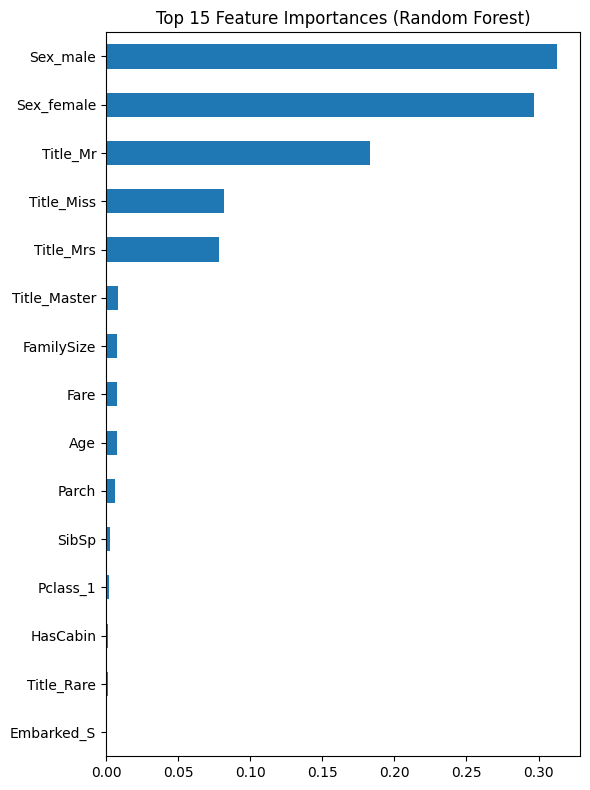

In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Use only the features you intentionally engineered
feature_cols = [
    'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'HasCabin',
    'Sex_female', 'Sex_male',
    'Embarked_C', 'Embarked_Q', 'Embarked_S',
    'Pclass_1', 'Pclass_2', 'Pclass_3',
    'Title_Master', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare'
]

X = df[feature_cols]
y = df['Survived']

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Random Forest
rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=5,
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)

# Evaluate
y_pred = rf.predict(X_test)
print("Test accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification report:\n", classification_report(y_test, y_pred))

# Cross-validation for a more reliable estimate
cv_scores = cross_val_score(rf, X, y, cv=5, scoring='accuracy')
print("\n5-fold CV accuracy scores:", cv_scores)
print("Mean CV accuracy:", cv_scores.mean())



import matplotlib.pyplot as plt

importances = rf.feature_importances_
feat_imp = (
    pd.Series(importances, index=feature_cols)
    .sort_values(ascending=False)
)

feat_imp.head(15).plot(kind='barh', figsize=(6, 8))
plt.gca().invert_yaxis()
plt.title("Top 15 Feature Importances (Random Forest)")
plt.tight_layout()
plt.show()

In [ ]:
!pip install shap -q




import shap

explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_test)

# Global importance
shap.summary_plot(shap_values[1], X_test, plot_type="bar", max_display=15)
plt.title("SHAP Feature Importance")
plt.show()

# Summary plot (distribution of impacts)
shap.summary_plot(shap_values[1], X_test, max_display=15)
plt.title("SHAP Summary Plot")
plt.show()

# Local explanation for one passenger
idx = 0  # change to inspect other passengers
shap.force_plot(
    explainer,
    shap_values[1][idx],
    X_test.iloc[idx],
    matplotlib=True
)
plt.show()

AssertionError: The shape of the shap_values matrix does not match the shape of the provided data matrix.

In [ ]:
import shap
import numpy as np

# Re-define features and split (same as before)
feature_cols = [
    'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'HasCabin',
    'Sex_female', 'Sex_male',
    'Embarked_C', 'Embarked_Q', 'Embarked_S',
    'Pclass_1', 'Pclass_2', 'Pclass_3',
    'Title_Master', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare'
]

X = df[feature_cols]
y = df['Survived']

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=5,
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)

explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_test)

print("Type of shap_values:", type(shap_values))
if isinstance(shap_values, list):
    print("Length of list:", len(shap_values))
    for i, arr in enumerate(shap_values):
        print(f"shap_values[{i}] shape:", arr.shape)
else:
    print("shap_values shape:", np.array(shap_values).shape)

print("X_test shape:", X_test.shape)

Type of shap_values: <class 'numpy.ndarray'>
shap_values shape: (84, 19, 2)
X_test shape: (84, 19)


shap_vals_class1 shape: (84, 19)
X_test shape: (84, 19)


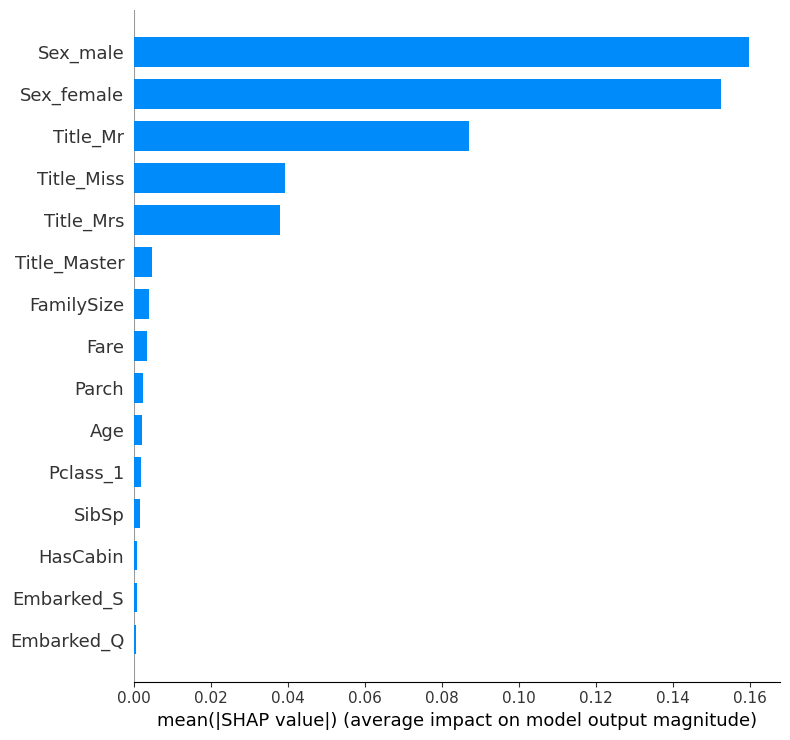

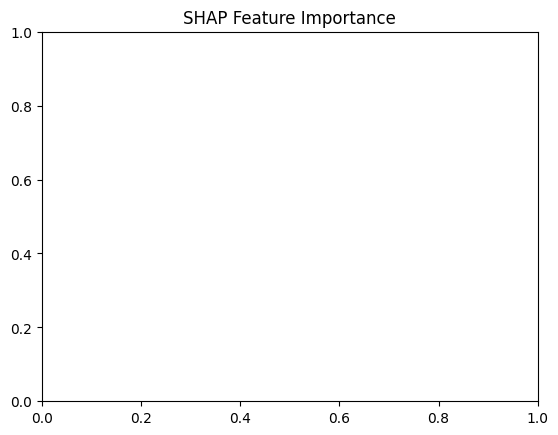

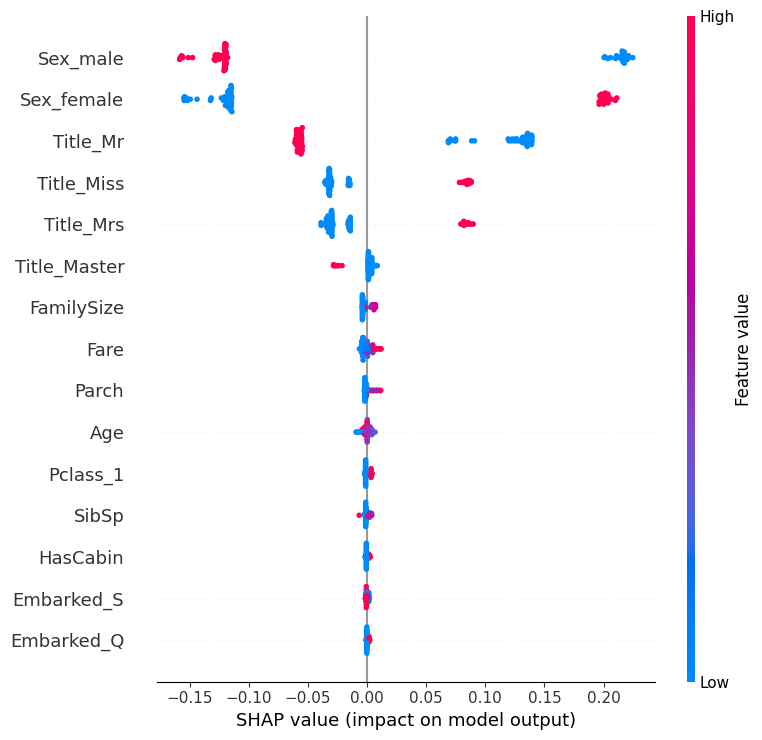

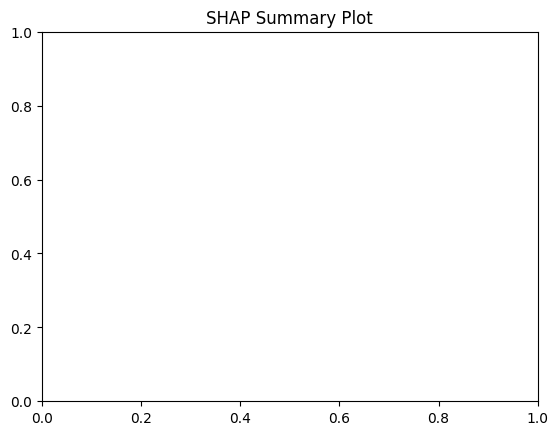

TypeError: unsupported operand type(s) for +: 'float' and 'TreeExplainer'

In [ ]:
import shap
import matplotlib.pyplot as plt
import numpy as np

# Features and split (same as before)
feature_cols = [
    'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'HasCabin',
    'Sex_female', 'Sex_male',
    'Embarked_C', 'Embarked_Q', 'Embarked_S',
    'Pclass_1', 'Pclass_2', 'Pclass_3',
    'Title_Master', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare'
]

X = df[feature_cols]
y = df['Survived']

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=5,
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)

explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_test)  # shape: (84, 19, 2)

# Select class 1 (survived): shape -> (84, 19)
shap_vals_class1 = shap_values[:, :, 1]

print("shap_vals_class1 shape:", shap_vals_class1.shape)
print("X_test shape:", X_test.shape)

# 1. Global feature importance (bar)
shap.summary_plot(shap_vals_class1, X_test, plot_type="bar", max_display=15)
plt.title("SHAP Feature Importance")
plt.show()

# 2. Summary plot (beeswarm)
shap.summary_plot(shap_vals_class1, X_test, max_display=15)
plt.title("SHAP Summary Plot")
plt.show()

# 3. Local explanation for one passenger
idx = 0  # change to inspect other passengers
shap.force_plot(
    explainer,
    shap_vals_class1[idx],
    X_test.iloc[idx],
    matplotlib=True
)
plt.show()

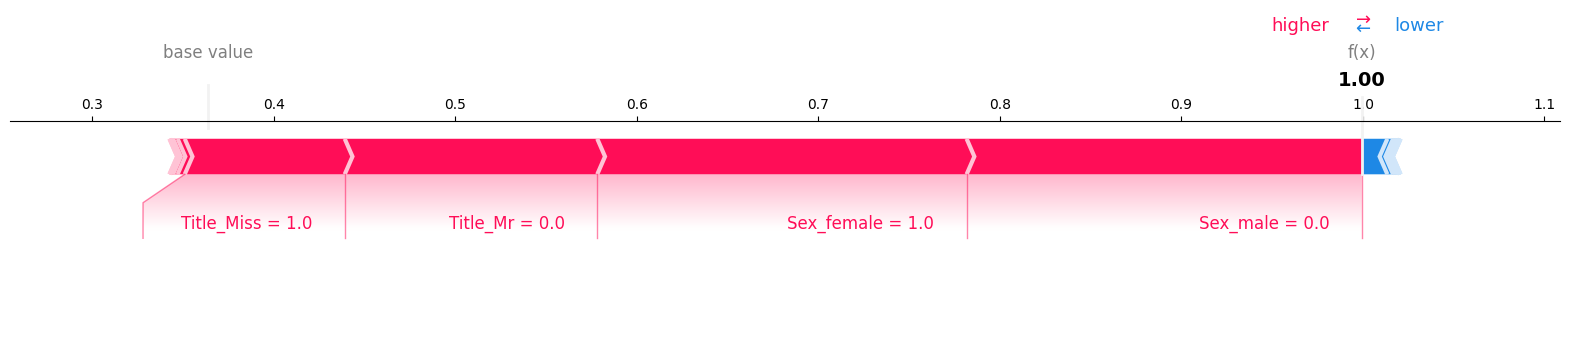

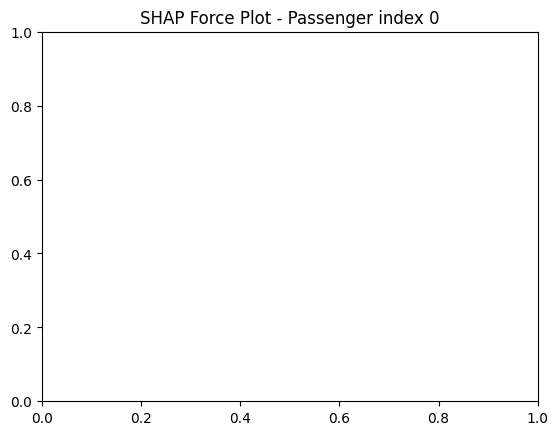

In [ ]:
import shap
import matplotlib.pyplot as plt
import numpy as np

# Assume these already exist from previous cells:
# rf, X_test, shap_vals_class1 (shape: 84, 19)

# Get base value for class 1 from the explainer
base_value = explainer.expected_value
# For binary classification, expected_value can be a scalar or array; ensure scalar for class 1
if isinstance(base_value, (list, np.ndarray)):
    base_value = float(base_value[1])

# Local explanation for one passenger
idx = 0  # change to inspect other passengers

shap_val_sample = shap_vals_class1[idx]      # shape: (19,)
x_sample = X_test.iloc[idx]                  # Series with 19 features
feature_names = x_sample.index.tolist()

# Force plot (correct API for your SHAP version)
shap.force_plot(
    base_value=base_value,
    shap_values=shap_val_sample,
    features=x_sample.values,
    feature_names=feature_names,
    matplotlib=True
)
plt.title(f"SHAP Force Plot - Passenger index {idx}")
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
import joblib
import os
import re

# -------------------------
# 1. Load and preprocess data
# -------------------------

df = pd.read_csv("/titanic.csv")  # adjust path if needed

# Extract title
def extract_title(name):
    title_search = re.search(r' ([A-Za-z]+)\.', name)
    if title_search:
        return title_search.group(1)
    return ""

df['Title'] = df['Name'].apply(extract_title)

rare_titles = ['Lady', 'Countess','Capt', 'Col', 'Don', 'Dr', 'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona']
df['Title'] = df['Title'].replace(rare_titles, 'Rare')
df['Title'] = df['Title'].replace(['Mlle', 'Ms'], 'Miss')
df['Title'] = df['Title'].replace('Mme', 'Mrs')

# Family size and cabin presence
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
df['HasCabin'] = df['Cabin'].notna().astype(int)

# Missing values
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df['Fare'] = df['Fare'].fillna(df['Fare'].median())

# Drop unused columns
drop_cols = ['Cabin', 'Name', 'Ticket', 'PassengerId']
df = df.drop(columns=[c for c in drop_cols if c in df.columns], errors='ignore')

# Encode categoricals
categorical_cols = ['Sex', 'Embarked', 'Pclass', 'Title']
df = pd.get_dummies(df, columns=categorical_cols, drop_first=False)

# -------------------------
# 2. Define features and split
# -------------------------

feature_cols = [
    'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'HasCabin',
    'Sex_female', 'Sex_male',
    'Embarked_C', 'Embarked_Q', 'Embarked_S',
    'Pclass_1', 'Pclass_2', 'Pclass_3',
    'Title_Master', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare'
]

X = df[feature_cols]
y = df['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# -------------------------
# 3. Train model
# -------------------------

rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=5,
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)

# -------------------------
# 4. Save model and features
# -------------------------

os.makedirs("models", exist_ok=True)
joblib.dump(rf, "models/titanic_model.pkl")
joblib.dump(feature_cols, "models/feature_cols.pkl")

print("Model and feature list saved to 'models/' folder.")

Model and feature list saved to 'models/' folder.


In [ ]:
import pandas as pd
import numpy as np
import joblib
import re

# Load model and feature list
model = joblib.load("models/titanic_model.pkl")
feature_cols = joblib.load("models/feature_cols.pkl")

def preprocess_one_passenger(passenger: dict) -> pd.DataFrame:
    df = pd.DataFrame([passenger])

    # Title
    def extract_title(name):
        title_search = re.search(r' ([A-Za-z]+)\.', name)
        if title_search:
            return title_search.group(1)
        return ""

    df['Title'] = df['Name'].apply(extract_title)

    rare_titles = ['Lady','Countess','Capt','Col','Don','Dr','Major','Rev','Sir','Jonkheer','Dona']
    df['Title'] = df['Title'].replace(rare_titles, 'Rare')
    df['Title'] = df['Title'].replace(['Mlle','Ms'], 'Miss')
    df['Title'] = df['Title'].replace('Mme', 'Mrs')

    # Family size & cabin
    df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
    df['HasCabin'] = df['Cabin'].notna().astype(int)

    # Impute missing numeric values
    df['Age'] = df['Age'].fillna(28.0)
    df['Fare'] = df['Fare'].fillna(14.45)

    # One-hot encode categoricals
    categorical_cols = ['Sex', 'Embarked', 'Pclass', 'Title']
    df = pd.get_dummies(df, columns=categorical_cols, drop_first=False)

    # Align columns with training
    for col in feature_cols:
        if col not in df.columns:
            df[col] = 0
    df = df[feature_cols]

    return df

# Example passenger
passenger = {
    "Pclass": 3,
    "Sex": "male",
    "Age": 22,
    "SibSp": 1,
    "Parch": 0,
    "Fare": 7.25,
    "Embarked": "S",
    "Name": "Smith, Mr. John",
    "Cabin": np.nan
}

X_new = preprocess_one_passenger(passenger)

pred = model.predict(X_new)[0]
prob = model.predict_proba(X_new)[0, 1]

print("Predicted survival (0 = No, 1 = Yes):", pred)
print("Probability of survival:", prob)

Predicted survival (0 = No, 1 = Yes): 0
Probability of survival: 0.0032442512442512447
